In [54]:
# Importing the Libraries
import pandas as pd
import numpy as np
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Importing the California Housing dataset
from pathlib import Path
from sklearn.datasets import fetch_california_housing

data_home_candidates = [
    Path.cwd() / "sklearn_data",
    Path.cwd() / "notebooks" / "sklearn_data",
    Path.home() / "scikit_learn_data",
]
data_home = next(
    (path for path in data_home_candidates if (path / "cal_housing_py3.pkz").exists()),
    data_home_candidates[-1],
)

housing = fetch_california_housing(data_home=data_home, download_if_missing=False)
'''
这里课件使用的是波士顿房价数据，但是新版导入有bug，我引入的是较新的加州房价数据，
因为我是固定了内核上面有些代码是为了手动下载到本地缓存再进行读取，
如果你是使用PyCharm配置的是anaconda应该可以直接下载具体代码跟课件类似可以问下ai
后续代码使用的数据都是以洛杉矶房价为例子的演示
'''

'\n这里课件使用的是波士顿房价数据，但是新版导入有bug，我引入的是较新的加州房价数据，\n因为我是固定了内核上面有些代码是为了手动下载到本地缓存再进行读取，\n如果你是使用PyCharm配置的是anaconda应该可以直接下载具体代码跟课件类似可以问下ai\n后续代码使用的数据都是以洛杉矶房价为例子的演示\n'

In [9]:
# Initializing the dataframe

df = pd.DataFrame(housing.data, columns=housing.feature_names)
df["MedHouseVal"] = housing.target

df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [10]:
Data_numpy = np.array(housing.data)

print(Data_numpy)
print(Data_numpy.shape)

[[   8.3252       41.            6.98412698 ...    2.55555556
    37.88       -122.23      ]
 [   8.3014       21.            6.23813708 ...    2.10984183
    37.86       -122.22      ]
 [   7.2574       52.            8.28813559 ...    2.80225989
    37.85       -122.24      ]
 ...
 [   1.7          17.            5.20554273 ...    2.3256351
    39.43       -121.22      ]
 [   1.8672       18.            5.32951289 ...    2.12320917
    39.43       -121.32      ]
 [   2.3886       16.            5.25471698 ...    2.61698113
    39.37       -121.24      ]]
(20640, 8)


In [11]:
print(housing.feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [12]:
Data_numpy = np.array(housing.data)

print(Data_numpy)
print(Data_numpy.shape)

[[   8.3252       41.            6.98412698 ...    2.55555556
    37.88       -122.23      ]
 [   8.3014       21.            6.23813708 ...    2.10984183
    37.86       -122.22      ]
 [   7.2574       52.            8.28813559 ...    2.80225989
    37.85       -122.24      ]
 ...
 [   1.7          17.            5.20554273 ...    2.3256351
    39.43       -121.22      ]
 [   1.8672       18.            5.32951289 ...    2.12320917
    39.43       -121.32      ]
 [   2.3886       16.            5.25471698 ...    2.61698113
    39.37       -121.24      ]]
(20640, 8)


In [13]:
Label_numpy = np.array(housing.target)

print(Label_numpy)
print(Label_numpy.shape)

[4.526 3.585 3.521 ... 0.923 0.847 0.894]
(20640,)


In [49]:
# Splitting to training and testing data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    Data_numpy, Label_numpy, test_size=0.2,random_state=42
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16512, 8)
(4128, 8)
(16512,)
(4128,)


In [15]:
# Import library for Linear Regression
from sklearn.linear_model import LinearRegression

In [16]:
# Create a Linear regressor
LR_program = LinearRegression()

In [17]:
# Train the model using the training sets
LR_program.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[ 0.43, 0.01,-0.1 ,...,-0.01,-0.42,-0.43]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-36.52
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[142770.5 , 1544.51, 655.46,..., 225.81, 64.46, 22.78]"


In [18]:
# Model prediction on train data
y_pred = LR_program.predict(X_test)

In [20]:
print(y_pred[0])
print(y_test[0])#比较预测值与真实值

2.3296854519153314
1.695


In [22]:
import scipy

distance = scipy.spatial.distance.euclidean(y_pred, y_test)

print(distance)#两个矢量间的欧氏距离

47.69816179768552


In [50]:
# Model Evaluation
print('R^2:', metrics.r2_score(y_test, y_pred))
print('Adjusted R^2:', (1 - (1 - metrics.r2_score(y_test, y_pred)) * (len(y_test) - 1) / (len(y_test) - X_train.shape[1] - 1)))
print('MAE:', metrics.mean_absolute_error(y_test, y_pred))
print('MSE:', metrics.mean_squared_error(y_test, y_pred))
print('RMSE:', np.sqrt(metrics.mean_squared_error(y_test, y_pred)))

R^2: -0.8556234909605667
Adjusted R^2: -0.859227518134076
MAE: 1.2070888225607892
MSE: 2.4316256827894476
RMSE: 1.5593670776277944


In [25]:
print(LR_program.coef_)#特征权重
print(LR_program.intercept_)#回归器截距
print(LR_program.n_features_in_)#所使用的特征数量

[ 4.32409573e-01  9.32380449e-03 -9.96631182e-02  5.93653586e-01
 -6.83633493e-06 -8.60865218e-03 -4.17255071e-01 -4.30219662e-01]
-36.520490214719445
8


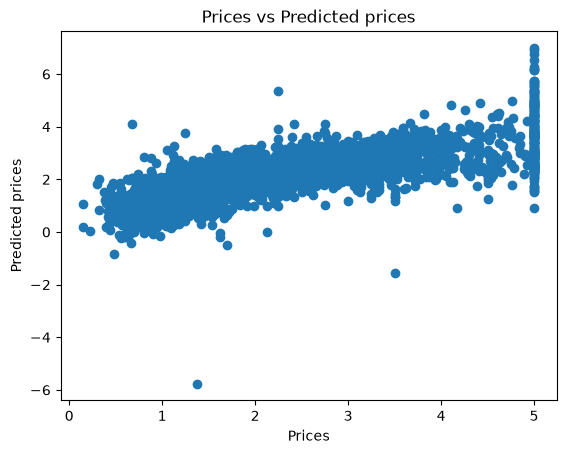

In [26]:
# Visualizing the differences between actual prices and predicted values 真实价格与预测价格
plt.scatter(y_test, y_pred)
plt.xlabel("Prices")
plt.ylabel("Predicted prices")
plt.title("Prices vs Predicted prices")
plt.show()

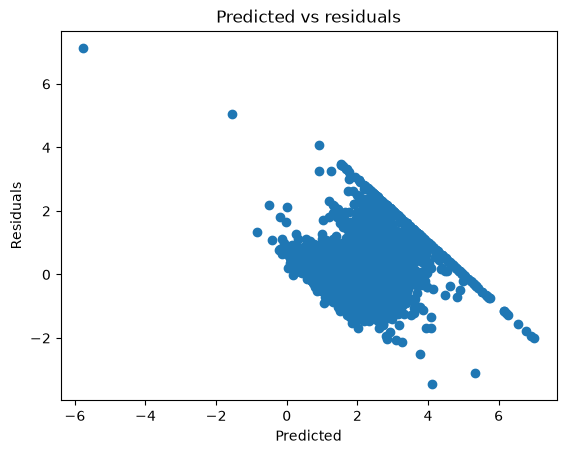

In [27]:
# Checking residuals 预测1价格与残差
plt.scatter(y_pred, y_test - y_pred)
plt.title("Predicted vs residuals")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()

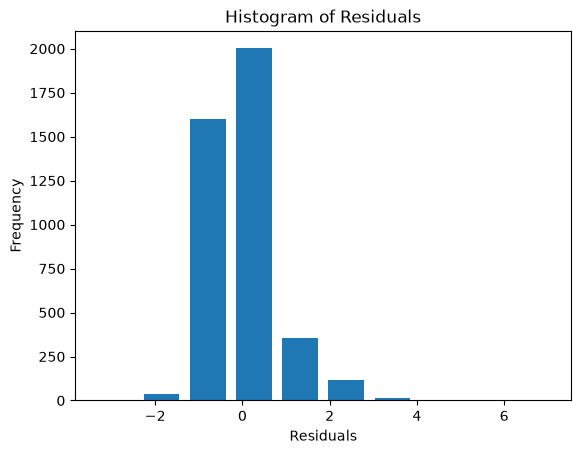

In [28]:
# Checking Normality of errors 残差分布直方图
plt.hist(y_test - y_pred, bins=10, rwidth=0.77)
plt.title("Histogram of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

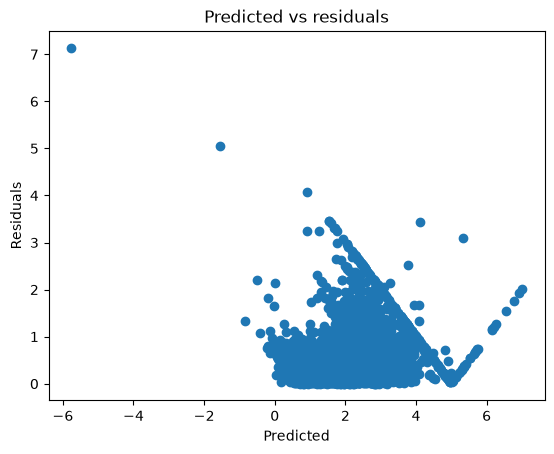

'\n它主要用来观察：\n\n模型在不同预测值范围内的误差大小；\n是否存在某些预测区间误差特别大；\n是否存在异方差现象。\n如果模型比较稳定，点应该比较均匀地分布，没有明显上升或扩散趋势。\n\n如果出现下面这种情况：\n\n预测值越大，残差也越大；\n点呈现漏斗形；\n某些区域误差明显偏大；\n说明模型在某些范围内预测不稳定，可能需要改进模型或处理数据。\n'

In [30]:
# Checking residuals 检查残差
plt.scatter(y_pred, np.abs(y_test - y_pred))
plt.title("Predicted vs residuals")
plt.xlabel("Predicted")
plt.ylabel("Residuals")
plt.show()
'''
它主要用来观察：

模型在不同预测值范围内的误差大小；
是否存在某些预测区间误差特别大；
是否存在异方差现象。
如果模型比较稳定，点应该比较均匀地分布，没有明显上升或扩散趋势。

如果出现下面这种情况：

预测值越大，残差也越大；
点呈现漏斗形；
某些区域误差明显偏大；
说明模型在某些范围内预测不稳定，可能需要改进模型或处理数据。
'''

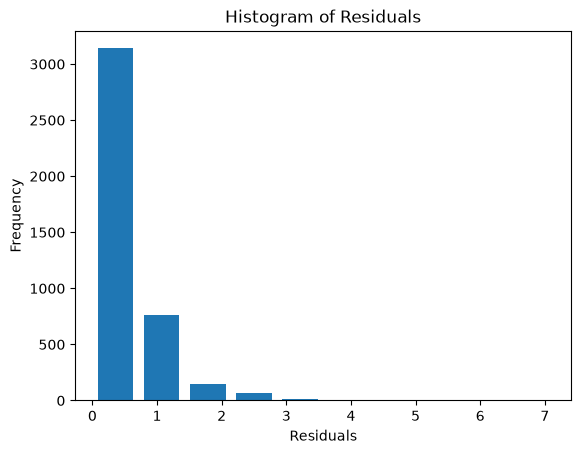

In [32]:
# Checking Normality of errors 绝对残差直方图
plt.hist(np.abs(y_test - y_pred), bins=10, rwidth=0.77)
plt.title("Histogram of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

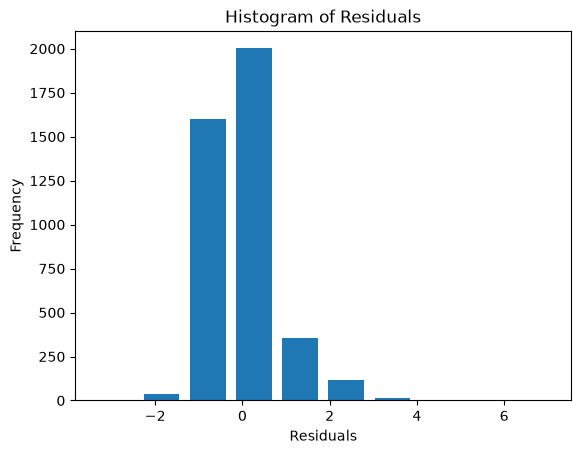

In [33]:
residuals = y_test - y_pred #检查误差正态性

plt.hist(residuals, bins=10, rwidth=0.77)
plt.title("Histogram of Residuals")
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.show()

In [53]:
from sklearn.tree import DecisionTreeRegressor #引入回归器

DT_program = DecisionTreeRegressor(  #设定控制参数
    criterion='squared_error',
    splitter='best',
    max_depth=10,
    min_samples_split=10,
    max_features=1.0,
    random_state=42
)

DT_program.fit(X_train, y_train)  #机器学习训练

y_pred_DT = DT_program.predict(X_test)  #机器学习预测

print('MSE of decision tree:', metrics.mean_squared_error(y_test, y_pred_DT))  #机器学习质量评价

MSE of decision tree: 0.41691362954537586


In [38]:
'''
课堂练习：

使用决策树回归器，根据特征值，预测波士顿房价(实际使用的还是加州房价数据)
测试不同参数的效果
可视化计算结果
'''

'\n课堂练习：\n\n使用决策树回归器，根据特征值，预测波士顿房价(实际使用的还是洛杉矶房价数据)\n测试不同参数的效果\n可视化计算结果\n'

In [37]:
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics
import matplotlib.pyplot as plt
import numpy as np

# 创建决策树回归模型
DT_program = DecisionTreeRegressor(
    criterion='squared_error',
    splitter='best',
    max_depth=10,
    min_samples_split=10,
    max_features=13,
    random_state=42
)

# 训练模型
DT_program.fit(X_train, y_train)

# 使用测试集进行预测
y_pred_DT = DT_program.predict(X_test)

# 模型评价
print('MSE of decision tree:', metrics.mean_squared_error(y_test, y_pred_DT))
print('RMSE of decision tree:', np.sqrt(metrics.mean_squared_error(y_test, y_pred_DT)))
print('MAE of decision tree:', metrics.mean_absolute_error(y_test, y_pred_DT))
print('R^2 of decision tree:', metrics.r2_score(y_test, y_pred_DT))

MSE of decision tree: 0.37665211087089134
RMSE of decision tree: 0.6137198961015451
MAE of decision tree: 0.40245573027755477
R^2 of decision tree: 0.7125370985361686


In [39]:
'''
| 参数                                  | 含义                               |
|---------------------------------------|------------------------------------|
| `criterion='squared_error'`           | 使用平方误差作为划分标准           |
| `splitter='best'`                     | 每次分裂时选择最优划分             |
| `max_depth=10`                        | 决策树最大深度为 10                |
| `min_samples_split=10`                | 一个节点至少有 10 个样本才继续分裂 |
| `max_features=13`                     | 每次分裂最多考虑 13 个特征         |
| `random_state=42`                     | 固定随机种子，保证结果可复现       |
'''

"\n| 参数                                  | 含义                               |\n|---------------------------------------|------------------------------------|\n| `criterion='squared_error'`           | 使用平方误差作为划分标准           |\n| `splitter='best'`                     | 每次分裂时选择最优划分             |\n| `max_depth=10`                        | 决策树最大深度为 10                |\n| `min_samples_split=10`                | 一个节点至少有 10 个样本才继续分裂 |\n| `max_features=13`                     | 每次分裂最多考虑 13 个特征         |\n| `random_state=42`                     | 固定随机种子，保证结果可复现       |\n"

In [41]:
from sklearn.tree import DecisionTreeRegressor
from sklearn import metrics
import numpy as np

# 测试不同 max_depth 的效果
depth_list = [2, 3, 4, 5, 6, 8, 10, 12, None]

for depth in depth_list:
    DT_model = DecisionTreeRegressor(
        criterion='squared_error',
        splitter='best',
        max_depth=depth,
        min_samples_split=10,
        random_state=42
    )
    
    # 训练模型
    DT_model.fit(X_train, y_train)
    
    # 预测
    y_pred = DT_model.predict(X_test)
    
    # 评价指标
    mse = metrics.mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = metrics.r2_score(y_test, y_pred)
    
    print("max_depth =", depth)
    print("MSE:", mse)
    print("RMSE:", rmse)
    print("R^2:", r2)
    print("-------------------------")

max_depth = 2
MSE: 0.7729585288344438
RMSE: 0.8791806008064804
R^2: 0.4100739249908828
-------------------------
max_depth = 3
MSE: 0.6658802089283934
RMSE: 0.816014833767373
R^2: 0.4917966702926254
-------------------------
max_depth = 4
MSE: 0.6016211670071308
RMSE: 0.7756424221296375
R^2: 0.540839514080919
-------------------------
max_depth = 5
MSE: 0.5348968887082463
RMSE: 0.7313664530919136
R^2: 0.5917638394312481
-------------------------
max_depth = 6
MSE: 0.48057269838832156
RMSE: 0.6932335092797531
R^2: 0.6332243514483753
-------------------------
max_depth = 8
MSE: 0.3953591794877147
RMSE: 0.6287759374274072
R^2: 0.6982597639155262
-------------------------
max_depth = 10
MSE: 0.37665211087089134
RMSE: 0.6137198961015451
R^2: 0.7125370985361686
-------------------------
max_depth = 12
MSE: 0.39148360339961413
RMSE: 0.625686505687644
R^2: 0.7012176242725365
-------------------------
max_depth = None
MSE: 0.44003097581471173
RMSE: 0.6633483065590141
R^2: 0.6641660105151592
---

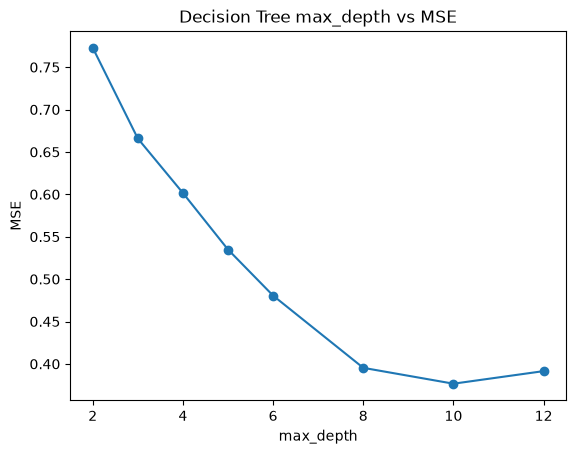

In [42]:
depth_list = [2, 3, 4, 5, 6, 8, 10, 12]
mse_list = []

for depth in depth_list:
    DT_model = DecisionTreeRegressor(
        criterion='squared_error',
        splitter='best',
        max_depth=depth,
        min_samples_split=10,
        random_state=42
    )
    
    DT_model.fit(X_train, y_train)
    y_pred = DT_model.predict(X_test)
    
    mse = metrics.mean_squared_error(y_test, y_pred)
    mse_list.append(mse)

# 可视化不同 max_depth 下的 MSE
plt.plot(depth_list, mse_list, marker='o')
plt.xlabel("max_depth")
plt.ylabel("MSE")
plt.title("Decision Tree max_depth vs MSE")
plt.show()

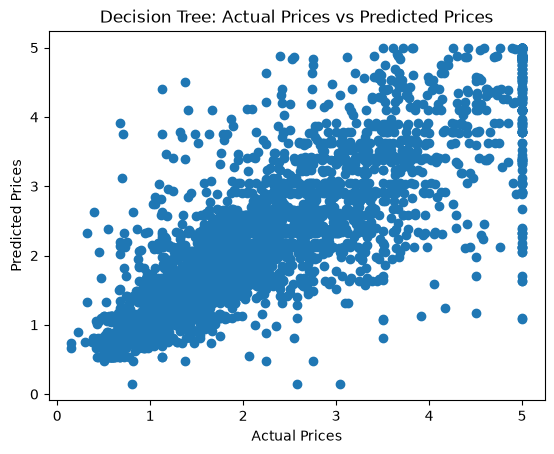

In [43]:
plt.scatter(y_test, y_pred_DT)
plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Decision Tree: Actual Prices vs Predicted Prices")
plt.show()

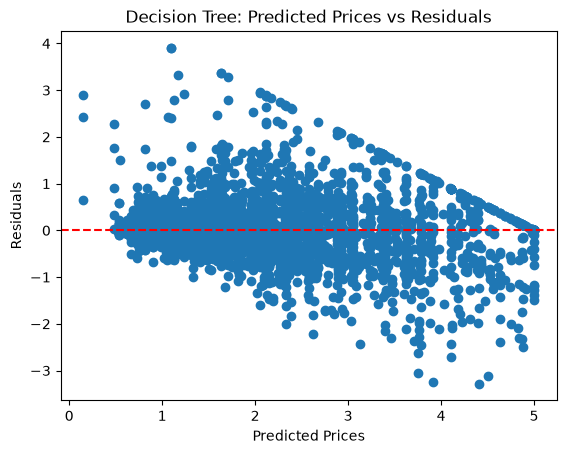

In [44]:
residuals_DT = y_test - y_pred_DT #可视化残差

plt.scatter(y_pred_DT, residuals_DT)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Decision Tree: Predicted Prices vs Residuals")
plt.show()

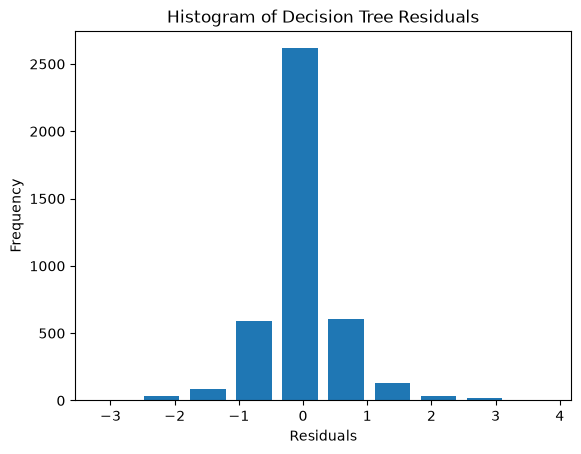

In [47]:
plt.hist(residuals_DT, bins=10, rwidth=0.77) #可视化残差分布
plt.xlabel("Residuals")
plt.ylabel("Frequency")
plt.title("Histogram of Decision Tree Residuals")
plt.show()

In [55]:
'''
可以看到效果并不理想，调整了一部分参数以及代码再次比较
'''

'\n可以看到效果并不理想，调整了一部分参数以及代码再次比较\n'

In [56]:
# 单元格 1：只用训练集进行交叉验证调参，测试集不参与调参

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

cv = KFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {
    "max_depth": [4, 6, 8, 10, 12, None],
    "min_samples_split": [2, 10, 25],
    "min_samples_leaf": [1, 3, 8, 15],
    "max_features": [1.0, 0.7, "sqrt"],
    "ccp_alpha": [0.0, 0.0005, 0.002],
}

tree_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)

tree_search.fit(X_train, y_train)

best_tree = tree_search.best_estimator_
y_pred_tree = best_tree.predict(X_test)

print("最佳参数：", tree_search.best_params_)
print(f"交叉验证 RMSE：{-tree_search.best_score_:.4f}")

最佳参数： {'ccp_alpha': 0.0, 'max_depth': None, 'max_features': 0.7, 'min_samples_leaf': 15, 'min_samples_split': 2}
交叉验证 RMSE：0.6056


In [57]:
# 单元格 2：在从未参与调参的测试集上，只评估一次最终模型

def evaluate_regression(name, y_true, y_pred):
    return {
        "Model": name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R²": r2_score(y_true, y_pred),
    }

# 对照模型：预测训练集房价均值
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
y_pred_baseline = baseline.predict(X_test)

# 线性回归基线
lr_model = LinearRegression().fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)

results = pd.DataFrame([
    evaluate_regression("Mean baseline", y_test, y_pred_baseline),
    evaluate_regression("Linear Regression", y_test, y_pred_lr),
    evaluate_regression("Tuned Decision Tree", y_test, y_pred_tree),
])

display(results.sort_values("RMSE").reset_index(drop=True))

,Model,MAE,RMSE,R²
0,Tuned Decision Tree,0.394534,0.596588,0.728392
1,Linear Regression,0.533200,0.745581,0.575788
2,Mean baseline,0.906069,1.144856,-0.000219


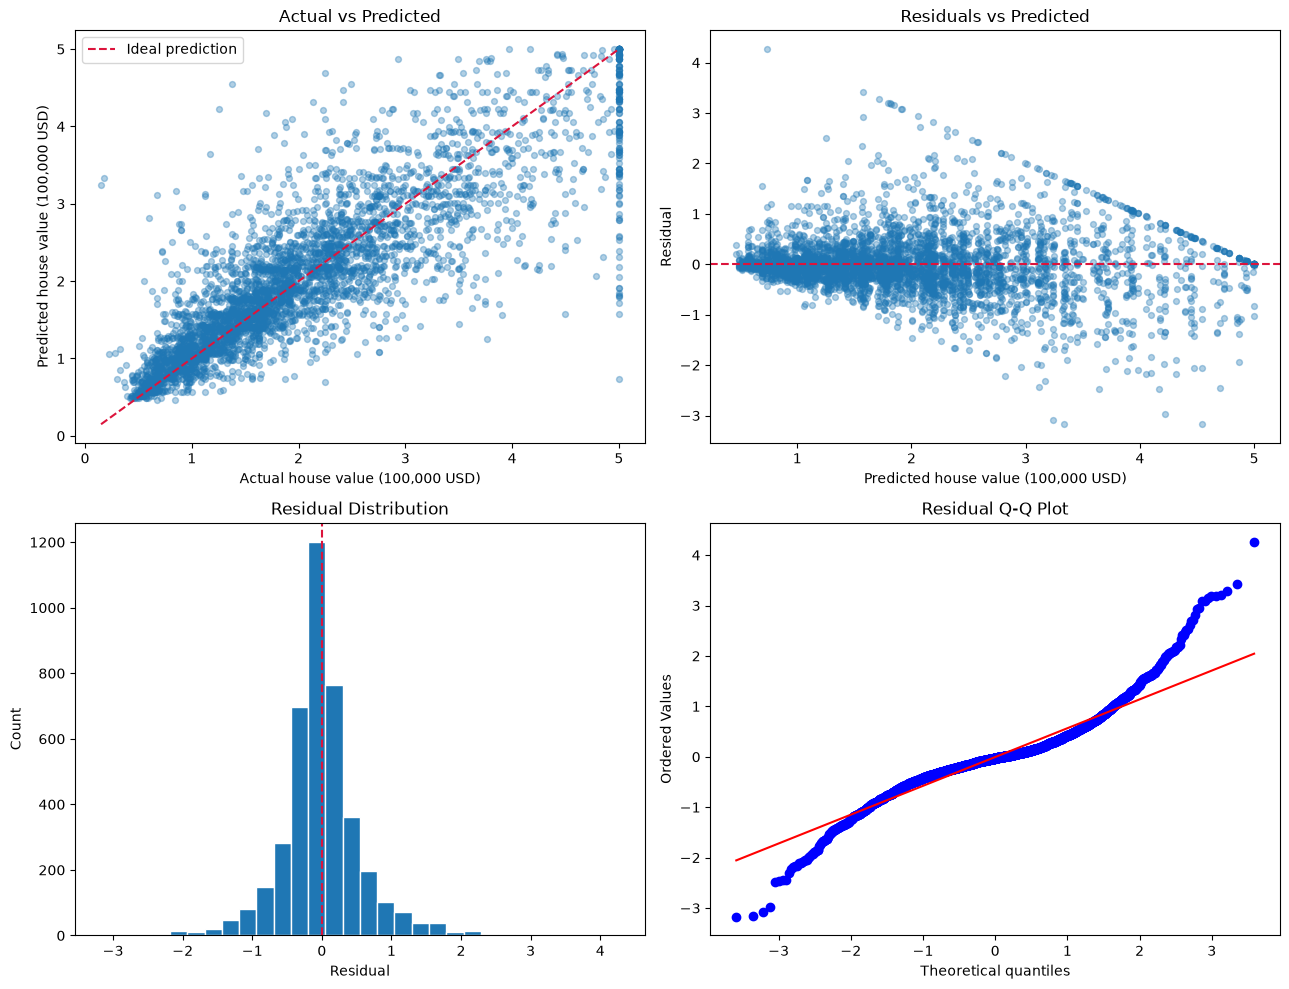

In [58]:
# 单元格 3：最终决策树的诊断可视化

from scipy import stats

residuals_tree = y_test - y_pred_tree

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# 真实值与预测值
min_price = min(y_test.min(), y_pred_tree.min())
max_price = max(y_test.max(), y_pred_tree.max())

axes[0, 0].scatter(y_test, y_pred_tree, alpha=0.35, s=18)
axes[0, 0].plot([min_price, max_price], [min_price, max_price],
                color="crimson", linestyle="--", label="Ideal prediction")
axes[0, 0].set_title("Actual vs Predicted")
axes[0, 0].set_xlabel("Actual house value (100,000 USD)")
axes[0, 0].set_ylabel("Predicted house value (100,000 USD)")
axes[0, 0].legend()

# 残差图
axes[0, 1].scatter(y_pred_tree, residuals_tree, alpha=0.35, s=18)
axes[0, 1].axhline(0, color="crimson", linestyle="--")
axes[0, 1].set_title("Residuals vs Predicted")
axes[0, 1].set_xlabel("Predicted house value (100,000 USD)")
axes[0, 1].set_ylabel("Residual")

# 残差直方图
axes[1, 0].hist(residuals_tree, bins=30, edgecolor="white")
axes[1, 0].axvline(0, color="crimson", linestyle="--")
axes[1, 0].set_title("Residual Distribution")
axes[1, 0].set_xlabel("Residual")
axes[1, 0].set_ylabel("Count")

# Q-Q 图：检查残差是否明显偏离正态分布
stats.probplot(residuals_tree, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Residual Q-Q Plot")

plt.tight_layout()
plt.show()

In [61]:
'''
这是 California Housing 数据集本身的“价格上限”造成的，不是你的绘图代码出错。
第一幅图横坐标是实际房价 y_test。该数据集将房价目标值截断在约 5.0（单位是 10 万美元，即约 50 万美元），
因此很多不同房屋的标签都被统一记成 5.0。它们会堆叠成横坐标 x=5 的蓝色竖线。
这正是一条向右下方倾斜的直线，所以第二张图的蓝色斜线是第一张图中 x=5 那批样本映射过来的结果。
'''

'\n这是 California Housing 数据集本身的“价格上限”造成的，不是你的绘图代码出错。\n第一幅图横坐标是实际房价 y_test。该数据集将房价目标值截断在约 5.0（单位是 10 万美元，即约 50 万美元），\n因此很多不同房屋的标签都被统一记成 5.0。它们会堆叠成横坐标 x=5 的蓝色竖线。\n这正是一条向右下方倾斜的直线，所以第二张图的蓝色斜线是第一张图中 x=5 那批样本映射过来的结果。\n'

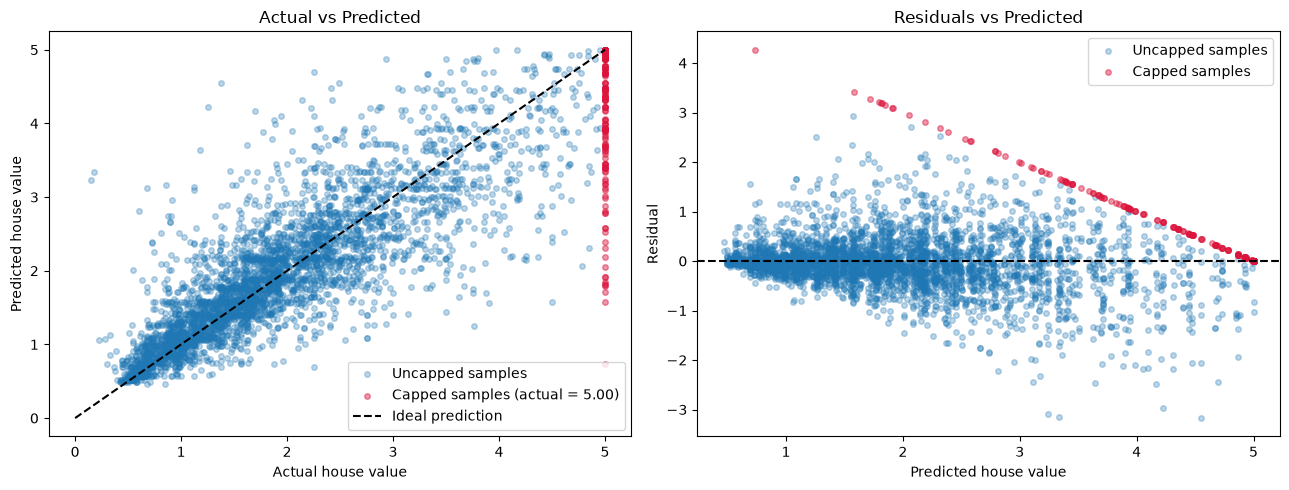

In [62]:
cap_value = housing.target.max()
is_capped = np.isclose(y_test, cap_value)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# 真实值 vs 预测值
axes[0].scatter(
    y_test[~is_capped], y_pred_tree[~is_capped],
    alpha=0.3, s=16, label="Uncapped samples"
)
axes[0].scatter(
    y_test[is_capped], y_pred_tree[is_capped],
    alpha=0.45, s=16, color="crimson",
    label=f"Capped samples (actual = {cap_value:.2f})"
)
axes[0].plot([0, cap_value], [0, cap_value], "k--", label="Ideal prediction")
axes[0].set_xlabel("Actual house value")
axes[0].set_ylabel("Predicted house value")
axes[0].set_title("Actual vs Predicted")
axes[0].legend()

# 残差图
axes[1].scatter(
    y_pred_tree[~is_capped], residuals_tree[~is_capped],
    alpha=0.3, s=16, label="Uncapped samples"
)
axes[1].scatter(
    y_pred_tree[is_capped], residuals_tree[is_capped],
    alpha=0.45, s=16, color="crimson",
    label="Capped samples"
)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Predicted house value")
axes[1].set_ylabel("Residual")
axes[1].set_title("Residuals vs Predicted")
axes[1].legend()

plt.tight_layout()
plt.show()

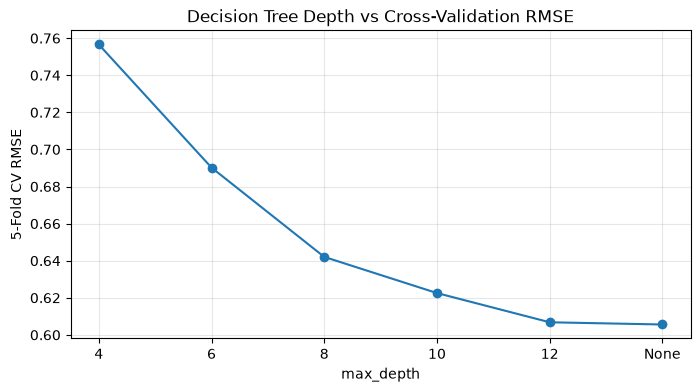

In [59]:
cv_results = pd.DataFrame(tree_search.cv_results_)

depth_order = ["4", "6", "8", "10", "12", "None"]
cv_results["max_depth"] = (
    cv_results["param_max_depth"]
    .where(cv_results["param_max_depth"].notna(), "None")
    .astype(str)
)

depth_summary = (
    cv_results.groupby("max_depth", as_index=False)["mean_test_score"]
    .max()
)

depth_summary["CV_RMSE"] = -depth_summary["mean_test_score"]
depth_summary["max_depth"] = pd.Categorical(
    depth_summary["max_depth"], categories=depth_order, ordered=True
)
depth_summary = depth_summary.sort_values("max_depth")

plt.figure(figsize=(8, 4))
plt.plot(depth_summary["max_depth"], depth_summary["CV_RMSE"], marker="o")
plt.xlabel("max_depth")
plt.ylabel("5-Fold CV RMSE")
plt.title("Decision Tree Depth vs Cross-Validation RMSE")
plt.grid(alpha=0.3)
plt.show()